#A model for an Analysis of Predictive Models for Customer Purchase Behaviour in E-Commerce Under Consumer Data Privacy Constraints

by Roselyn Mutambiranwa

In [ ]:
#IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving online_shoppers_intention.csv to online_shoppers_intention (1).csv


In [ ]:
df = pd.read_csv("online_shoppers_intention.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Number of rows: 12330
Number of columns: 18

Column names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype:

##EXAMINE TARGET VARIABLE

In [ ]:
# Count purchase and non-purchase sessions
revenue_counts = df['Revenue'].value_counts()

print(revenue_counts)

Revenue
False    10422
True      1908
Name: count, dtype: int64


In [ ]:
revenue_percentages = df['Revenue'].value_counts(normalize=True) * 100

print("\nPercentage distribution:")
print(revenue_percentages.round(2))


Percentage distribution:
Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


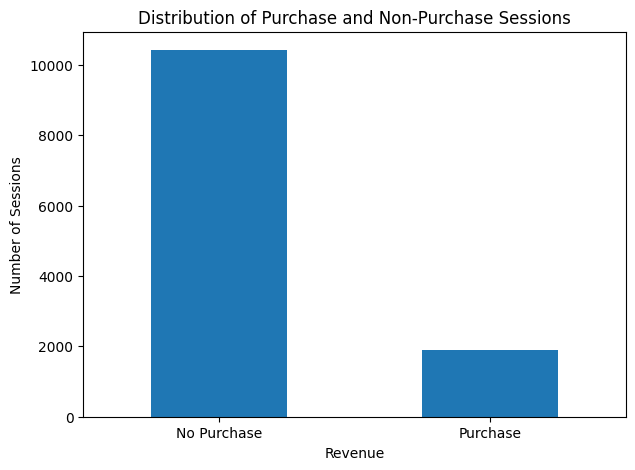

In [ ]:
plt.figure(figsize=(7, 5))

df['Revenue'].value_counts().plot(kind='bar')

plt.title('Distribution of Purchase and Non-Purchase Sessions')
plt.xlabel('Revenue')
plt.ylabel('Number of Sessions')
plt.xticks(
    ticks=[0, 1],
    labels=['No Purchase', 'Purchase'],
    rotation=0
)

plt.show()

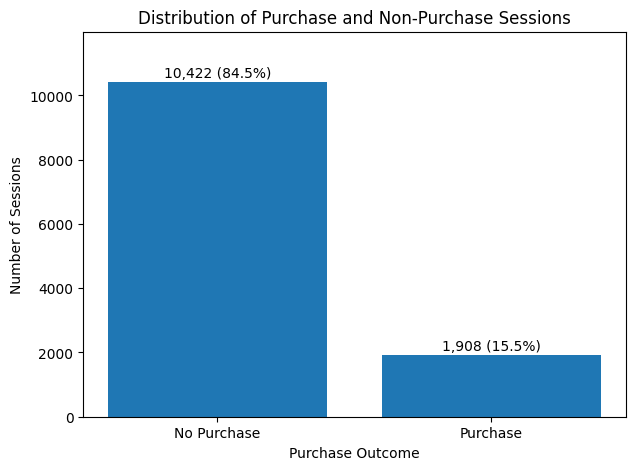

In [ ]:
# Calculate counts and percentages
revenue_counts = df['Revenue'].value_counts()

labels = ['No Purchase', 'Purchase']
counts = [
    revenue_counts[False],
    revenue_counts[True]
]

percentages = [
    (revenue_counts[False] / len(df)) * 100,
    (revenue_counts[True] / len(df)) * 100
]

plt.figure(figsize=(7, 5))

bars = plt.bar(labels, counts)

plt.title('Distribution of Purchase and Non-Purchase Sessions')
plt.xlabel('Purchase Outcome')
plt.ylabel('Number of Sessions')

# Add count and percentage labels
for bar, count, percentage in zip(bars, counts, percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 150,
        f'{count:,} ({percentage:.1f}%)',
        ha='center'
    )

plt.ylim(0, max(counts) * 1.15)
plt.show()

##INVESTIGATE THE DUPLICATES

In [ ]:
import pandas as pd

df = pd.read_csv("online_shoppers_intention.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:
# Identify duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print("Percentage of duplicate rows:",
      round((duplicate_count / len(df)) * 100, 2), "%")

Number of duplicate rows: 125
Percentage of duplicate rows: 1.01 %


In [ ]:
# Display all rows that belong to duplicate groups
duplicates = df[df.duplicated(keep=False)]

print("Number of rows involved in duplicate groups:", len(duplicates))

duplicates.head(10)

Number of rows involved in duplicate groups: 201


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False


In [ ]:
# Count how frequently each duplicated record occurs
duplicate_frequency = (
    duplicates
    .value_counts()
    .reset_index(name='Frequency')
)

duplicate_frequency.head(10)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Frequency
0,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False,14
1,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False,7
2,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,May,2,2,1,3,Returning_Visitor,False,False,7
3,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,May,1,1,1,3,Returning_Visitor,False,False,6
4,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,8,13,9,20,Other,False,False,5
5,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,1,1,Returning_Visitor,False,False,4
6,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,May,1,1,4,3,Returning_Visitor,False,False,4
7,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Nov,2,2,1,1,Returning_Visitor,False,False,4
8,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,1,Returning_Visitor,True,False,3
9,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,4,1,Returning_Visitor,True,False,3


In [ ]:
duplicate_frequency = (
    df[df.duplicated(keep=False)]
    .value_counts()
    .reset_index(name='Frequency')
)

print("Number of unique duplicated records:", len(duplicate_frequency))

print("\nFrequency summary:")
print(duplicate_frequency['Frequency'].value_counts().sort_index())

Number of unique duplicated records: 76

Frequency summary:
Frequency
2     54
3     14
4      3
5      1
6      1
7      2
14     1
Name: count, dtype: int64


In [ ]:
print("\nTotal rows involved in duplicate groups:",
      len(df[df.duplicated(keep=False)]))

print("Duplicate copies beyond the first occurrence:",
      df.duplicated().sum())


Total rows involved in duplicate groups: 201
Duplicate copies beyond the first occurrence: 125


tbc

In [ ]:
# Remove exact duplicate records
df_clean = df.drop_duplicates().copy()

print("Original number of rows:", len(df))
print("Duplicate copies removed:", df.duplicated().sum())
print("Cleaned number of rows:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())

Original number of rows: 12330
Duplicate copies removed: 125
Cleaned number of rows: 12205
Duplicates remaining: 0


In [ ]:
# Check purchase outcome after duplicate removal
revenue_counts_clean = df_clean['Revenue'].value_counts()

print("Purchase outcome counts:")
print(revenue_counts_clean)

print("\nPurchase outcome percentages:")
print(
    (df_clean['Revenue'].value_counts(normalize=True) * 100).round(2)
)

Purchase outcome counts:
Revenue
False    10297
True      1908
Name: count, dtype: int64

Purchase outcome percentages:
Revenue
False    84.37
True     15.63
Name: proportion, dtype: float64


##EXPLORATORY DATA ANALYSIS (EDA)

In [ ]:
# Summary statistics for the numeric behavioural variables
df_clean.describe().T


,count,mean,std,min,25%,50%,75%,max
Administrative,12205.0,2.338878,3.330436,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12205.0,81.646331,177.491845,0.0,0.000000,9.000000,94.700000,3398.750000
Informational,12205.0,0.508726,1.275617,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12205.0,34.825454,141.424807,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12205.0,32.045637,44.593649,0.0,8.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12205.0,1206.982457,1919.601400,0.0,193.000000,608.942857,1477.154762,63973.522230
BounceRates,12205.0,0.020370,0.045255,0.0,0.000000,0.002899,0.016667,0.200000
ExitRates,12205.0,0.041466,0.046163,0.0,0.014231,0.025000,0.048529,0.200000
PageValues,12205.0,5.949574,18.653671,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12205.0,0.061942,0.199666,0.0,0.000000,0.000000,0.000000,1.000000


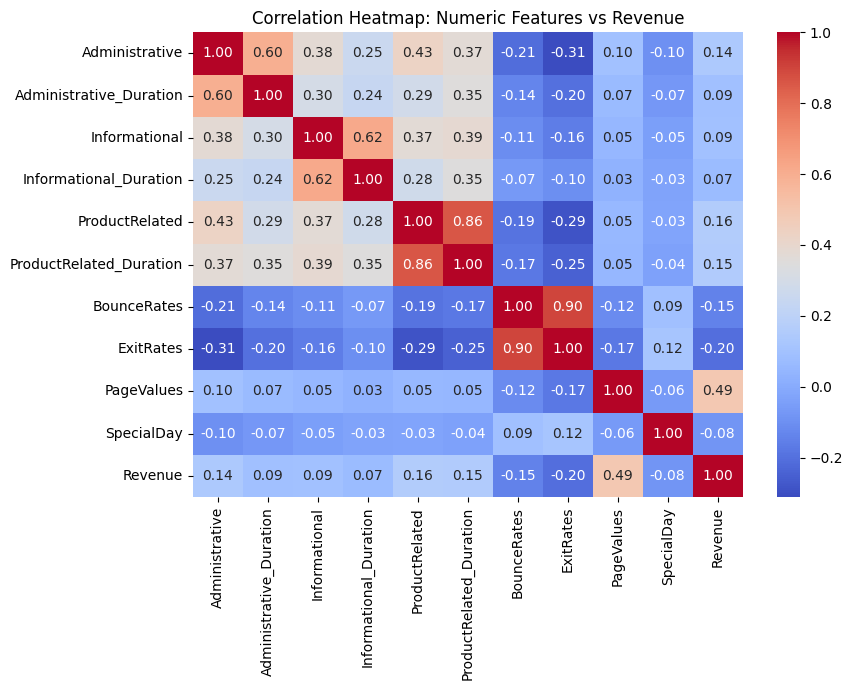

In [ ]:
# Correlation between numeric features and Revenue
numeric_cols = ['Administrative', 'Administrative_Duration', 'Informational',
                 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
                 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

corr = df_clean[numeric_cols + ['Revenue']].copy()
corr['Revenue'] = corr['Revenue'].astype(int)

plt.figure(figsize=(9, 7))
sns.heatmap(corr.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap: Numeric Features vs Revenue')
plt.tight_layout()
plt.show()


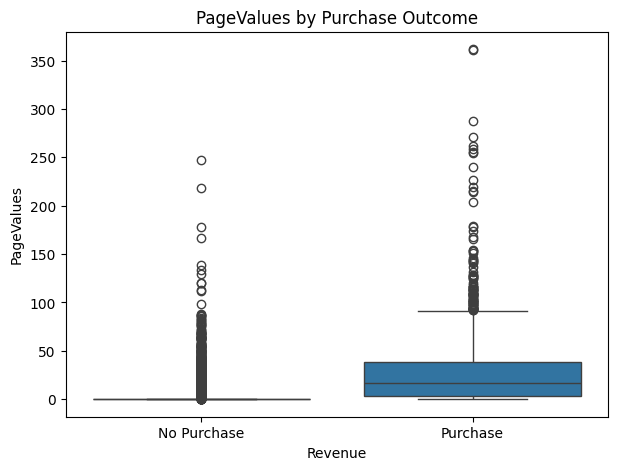

In [ ]:
# PageValues stands out as the feature most correlated with Revenue.
# Quick visual check: does PageValues really separate buyers from non-buyers?
plt.figure(figsize=(7, 5))
sns.boxplot(x='Revenue', y='PageValues', data=df_clean)
plt.xticks([0, 1], ['No Purchase', 'Purchase'])
plt.title('PageValues by Purchase Outcome')
plt.show()


##PRIVACY-PRESERVING DATA TRANSFORMATION

To answer the research question, we need two versions of the dataset:

1. **Original dataset** — all 17 features, as published.
2. **Privacy-restricted dataset** — simulates POPIA/GDPR-style constraints using the four techniques named in the proposal:
   - **Feature masking** — remove technical/device fields that could act as fingerprints (`OperatingSystems`, `Browser`, `TrafficType`, `Region`)
   - **Data minimisation** — drop the least essential behavioural counters (`Administrative`, `Administrative_Duration`, `Informational`, `Informational_Duration`)
   - **Feature aggregation** — convert the remaining continuous behavioural variables into broad quartile bands instead of exact values
   - **Anonymisation** — no direct identifiers exist in this public dataset, so this step is a formality

**Important methodological correction (after supervisor/reviewer feedback):** the aggregation step is *not* applied to the whole dataset up front. It is done **inside the modelling pipeline**, using bin boundaries learned from the training fold only, for two reasons:

- **Data leakage** — computing quartile edges from the full dataset (train + test combined) before splitting lets test-set information leak into the training process.
- **A zero-inflation bug** — `PageValues` (the single strongest predictor of `Revenue`, r≈0.49) is 0 for ~78% of sessions. A naive `pd.qcut` quartile split on the *whole column* puts the 25th, 50th and 75th percentiles all at exactly 0, which collapses the entire column into **one single band** — silently destroying all of its signal. The custom binner below keeps "zero" as its own band and only splits the *non-zero* values into further quartiles, so the zero/non-zero signal survives aggregation.

In [ ]:
# Target variable
y = df_clean['Revenue'].astype(int)

# ---- Version A: ORIGINAL ----
original_features = [c for c in df_clean.columns if c != 'Revenue']
X_original = df_clean[original_features].copy()

numeric_cols_orig = ['Administrative', 'Administrative_Duration', 'Informational',
                      'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
                      'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
categorical_cols_orig = ['Month', 'OperatingSystems', 'Browser', 'Region',
                          'TrafficType', 'VisitorType', 'Weekend']

print('Original feature count:', len(original_features))


Original feature count: 17


In [ ]:
# ---- Version B: PRIVACY-RESTRICTED ----
# Masking + minimisation are simple column drops (no leakage risk).
# Aggregation (the quartile binning) is now done INSIDE the modelling
# pipeline (see the ZeroAwareQuantileBinner below), so it is fit on the
# training fold only.
df_restricted = df_clean.drop(columns=['OperatingSystems', 'Browser', 'TrafficType', 'Region'])
df_restricted = df_restricted.drop(columns=['Administrative', 'Administrative_Duration',
                                             'Informational', 'Informational_Duration'])

restricted_features = [c for c in df_restricted.columns if c != 'Revenue']
X_restricted = df_restricted[restricted_features].copy()

bin_cols_restr = ['ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues']
numeric_cols_restr = ['ProductRelated', 'SpecialDay']
categorical_cols_restr = ['Month', 'VisitorType', 'Weekend']

print('Privacy-restricted feature count:', len(restricted_features))
print('Features removed by masking/minimisation:',
      set(original_features) - set(restricted_features))
print('Features aggregated inside the pipeline:', bin_cols_restr)


Privacy-restricted feature count: 9
Features removed by masking/minimisation: {'Informational_Duration', 'Administrative', 'Region', 'OperatingSystems', 'Browser', 'TrafficType', 'Informational', 'Administrative_Duration'}
Features aggregated inside the pipeline: ['ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues']


##TRAIN-TEST SPLIT, PREPROCESSING AND MODELS

Both dataset versions use:
- an 80:20 **stratified** train/test split (Revenue is imbalanced, ~15.6% purchases)
- **5-fold stratified cross-validation** on the training set for model development
- a **ColumnTransformer** that standardises numeric features, one-hot encodes categorical features, and (for the restricted dataset) discretises the aggregated columns using a **custom, leak-free, zero-aware quantile binner** fit only on each training fold
- `class_weight='balanced'` on every model to account for the class imbalance, instead of resampling, for this first pass

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class ZeroAwareQuantileBinner(BaseEstimator, TransformerMixin):
    """
    Privacy-style quartile aggregation, fit on TRAINING data only
    (avoids data leakage), and zero-aware: sessions with a value of
    exactly 0 keep their own band, and only the non-zero values are
    split into further quantile bands. This avoids the bug where a
    plain pd.qcut on a heavily zero-inflated column (like PageValues)
    collapses into a single, uninformative band.
    """
    def __init__(self, n_bins=4):
        self.n_bins = n_bins

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.nonzero_edges_ = []
        for j in range(X.shape[1]):
            nz = X[:, j][X[:, j] > 0]
            if len(nz) == 0:
                self.nonzero_edges_.append(np.array([-np.inf, np.inf]))
                continue
            qs = np.linspace(0, 1, self.n_bins)  # up to n_bins-1 non-zero bands
            edges = np.unique(np.quantile(nz, qs))
            edges[0], edges[-1] = -np.inf, np.inf
            self.nonzero_edges_.append(edges)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        out = np.zeros_like(X)
        for j in range(X.shape[1]):
            col = X[:, j]
            zero_mask = col <= 0
            edges = self.nonzero_edges_[j]
            nz_bins = np.digitize(col, edges[1:-1], right=True)
            out[:, j] = np.where(zero_mask, 0, nz_bins + 1)
        return out


In [ ]:
# Additional imports needed for one-hot encoding and ROC curves
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_curve

RANDOM_STATE = 42

def make_preprocessor(numeric_cols, categorical_cols, bin_cols=None):
    transformers = [
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
    ]
    if bin_cols:
        # Discretise the aggregated columns using the leak-free, zero-aware
        # binner defined above, fit only on the training fold, then scale.
        transformers.append((
            'bin',
            Pipeline([('discretize', ZeroAwareQuantileBinner(n_bins=4)),
                      ('scale', StandardScaler())]),
            bin_cols,
        ))
    return ColumnTransformer(transformers)

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced', max_depth=10),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, class_weight='balanced', n_jobs=-1),
    'SVM (RBF)': SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE, class_weight='balanced'),
}


In [ ]:
def run_experiment(X, y, numeric_cols, categorical_cols, bin_cols, label):
    print(f'=== {label} ===')
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
    )
    print('Train class balance:', round(y_train.mean(), 4),
          ' Test class balance:', round(y_test.mean(), 4))

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    results = []
    roc_data = {}

    for name, clf in models.items():
        pipe = Pipeline([
            ('prep', make_preprocessor(numeric_cols, categorical_cols, bin_cols)),
            ('clf', clf),
        ])

        # 5-fold CV accuracy on the training set only. Because the
        # ZeroAwareQuantileBinner is INSIDE this pipeline, its bin edges
        # are refit on each training fold separately - no leakage.
        cv_scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='accuracy')
        cv_acc = cv_scores.mean()

        # Fit on the full training set, evaluate once on the untouched test set
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)
        y_proba = pipe.predict_proba(X_test)[:, 1]

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        auc = roc_auc_score(y_test, y_proba)

        results.append({'Model': name, 'CV_Accuracy': round(cv_acc, 4),
                         'Test_Accuracy': round(acc, 4), 'Precision': round(prec, 4),
                         'Recall': round(rec, 4), 'F1': round(f1, 4), 'AUC': round(auc, 4)})
        roc_data[name] = roc_curve(y_test, y_proba)

        print(f'{name:22s} | CV Acc {cv_acc:.4f} | Test Acc {acc:.4f} | '
              f'Prec {prec:.4f} | Rec {rec:.4f} | F1 {f1:.4f} | AUC {auc:.4f}')

    return pd.DataFrame(results), roc_data


In [ ]:
results_original, roc_original = run_experiment(
    X_original, y, numeric_cols_orig, categorical_cols_orig, None, 'ORIGINAL DATASET'
)


=== ORIGINAL DATASET ===
Train class balance: 0.1563  Test class balance: 0.1565
Logistic Regression    | CV Acc 0.8471 | Test Acc 0.8460 | Prec 0.5050 | Rec 0.7958 | F1 0.6179 | AUC 0.9097
Decision Tree          | CV Acc 0.8444 | Test Acc 0.8533 | Prec 0.5218 | Rec 0.7513 | F1 0.6159 | AUC 0.8338
Random Forest          | CV Acc 0.8989 | Test Acc 0.8964 | Prec 0.7490 | Rec 0.5079 | F1 0.6053 | AUC 0.9239
SVM (RBF)              | CV Acc 0.8701 | Test Acc 0.8689 | Prec 0.5589 | Rec 0.7696 | F1 0.6476 | AUC 0.9095


In [ ]:
results_restricted, roc_restricted = run_experiment(
    X_restricted, y, numeric_cols_restr, categorical_cols_restr, bin_cols_restr,
    'PRIVACY-RESTRICTED DATASET (leak-free, zero-aware binning)'
)


=== PRIVACY-RESTRICTED DATASET (leak-free, zero-aware binning) ===
Train class balance: 0.1563  Test class balance: 0.1565
Logistic Regression    | CV Acc 0.8733 | Test Acc 0.8796 | Prec 0.5840 | Rec 0.8010 | F1 0.6755 | AUC 0.9258
Decision Tree          | CV Acc 0.8405 | Test Acc 0.8300 | Prec 0.4727 | Rec 0.7487 | F1 0.5795 | AUC 0.8235
Random Forest          | CV Acc 0.8782 | Test Acc 0.8746 | Prec 0.6056 | Rec 0.5707 | F1 0.5876 | AUC 0.8883
SVM (RBF)              | CV Acc 0.8581 | Test Acc 0.8603 | Prec 0.5333 | Rec 0.8586 | F1 0.6580 | AUC 0.9102


##RESULTS COMPARISON

In [ ]:
print('Original dataset results:')
display(results_original)

print('\nPrivacy-restricted dataset results:')
display(results_restricted)


Original dataset results:


,Model,CV_Accuracy,Test_Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.8471,0.8460,0.5050,0.7958,0.6179,0.9097
1,Decision Tree,0.8444,0.8533,0.5218,0.7513,0.6159,0.8338
2,Random Forest,0.8989,0.8964,0.7490,0.5079,0.6053,0.9239
3,SVM (RBF),0.8701,0.8689,0.5589,0.7696,0.6476,0.9095



Privacy-restricted dataset results:


,Model,CV_Accuracy,Test_Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.8733,0.8796,0.5840,0.8010,0.6755,0.9258
1,Decision Tree,0.8405,0.8300,0.4727,0.7487,0.5795,0.8235
2,Random Forest,0.8782,0.8746,0.6056,0.5707,0.5876,0.8883
3,SVM (RBF),0.8581,0.8603,0.5333,0.8586,0.6580,0.9102


In [ ]:
# Per-model comparison table: original vs privacy-restricted, with deltas.
# Negative *_Change values mean performance dropped under the privacy-restricted condition.
comparison = results_original.merge(
    results_restricted, on='Model', suffixes=('_Original', '_Restricted')
)

for metric in ['Test_Accuracy', 'Precision', 'Recall', 'F1', 'AUC']:
    comparison[metric + '_Change'] = (
        comparison[metric + '_Restricted'] - comparison[metric + '_Original']
    ).round(4)

display(comparison)


,Model,CV_Accuracy_Original,Test_Accuracy_Original,Precision_Original,Recall_Original,F1_Original,AUC_Original,CV_Accuracy_Restricted,Test_Accuracy_Restricted,Precision_Restricted,Recall_Restricted,F1_Restricted,AUC_Restricted,Test_Accuracy_Change,Precision_Change,Recall_Change,F1_Change,AUC_Change
0,Logistic Regression,0.8471,0.8460,0.5050,0.7958,0.6179,0.9097,0.8733,0.8796,0.5840,0.8010,0.6755,0.9258,0.0336,0.0790,0.0052,0.0576,0.0161
1,Decision Tree,0.8444,0.8533,0.5218,0.7513,0.6159,0.8338,0.8405,0.8300,0.4727,0.7487,0.5795,0.8235,-0.0233,-0.0491,-0.0026,-0.0364,-0.0103
2,Random Forest,0.8989,0.8964,0.7490,0.5079,0.6053,0.9239,0.8782,0.8746,0.6056,0.5707,0.5876,0.8883,-0.0218,-0.1434,0.0628,-0.0177,-0.0356
3,SVM (RBF),0.8701,0.8689,0.5589,0.7696,0.6476,0.9095,0.8581,0.8603,0.5333,0.8586,0.6580,0.9102,-0.0086,-0.0256,0.0890,0.0104,0.0007


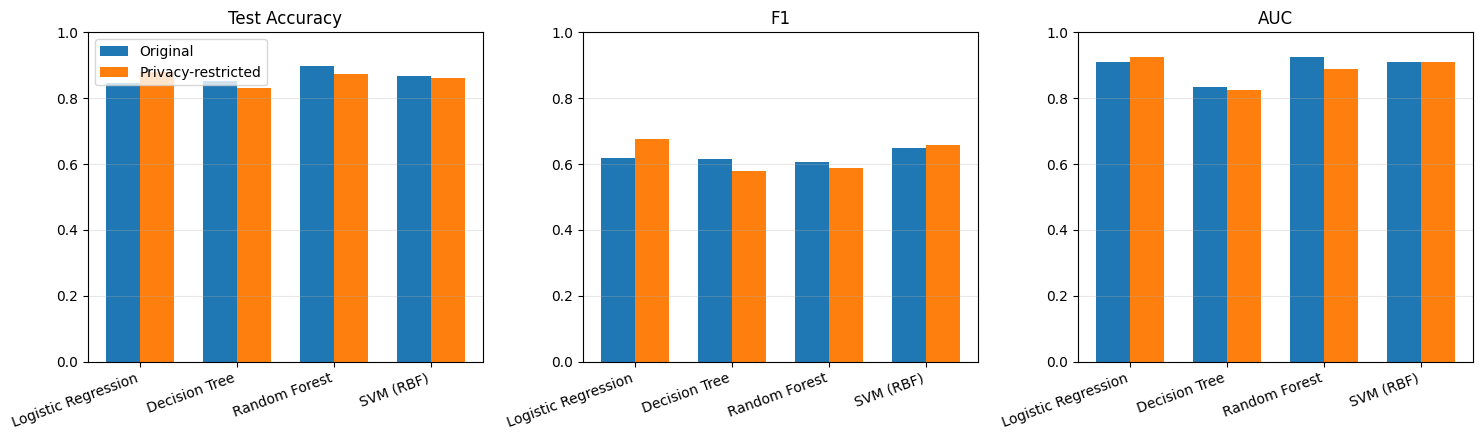

In [ ]:
# Grouped bar chart comparing key metrics across both dataset versions
metrics = ['Test_Accuracy', 'F1', 'AUC']
model_names = results_original['Model'].tolist()
x = np.arange(len(model_names))
width = 0.35

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, metric in zip(axes, metrics):
    ax.bar(x - width/2, results_original[metric], width, label='Original')
    ax.bar(x + width/2, results_restricted[metric], width, label='Privacy-restricted')
    ax.set_title(metric.replace('_', ' '))
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, rotation=20, ha='right')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


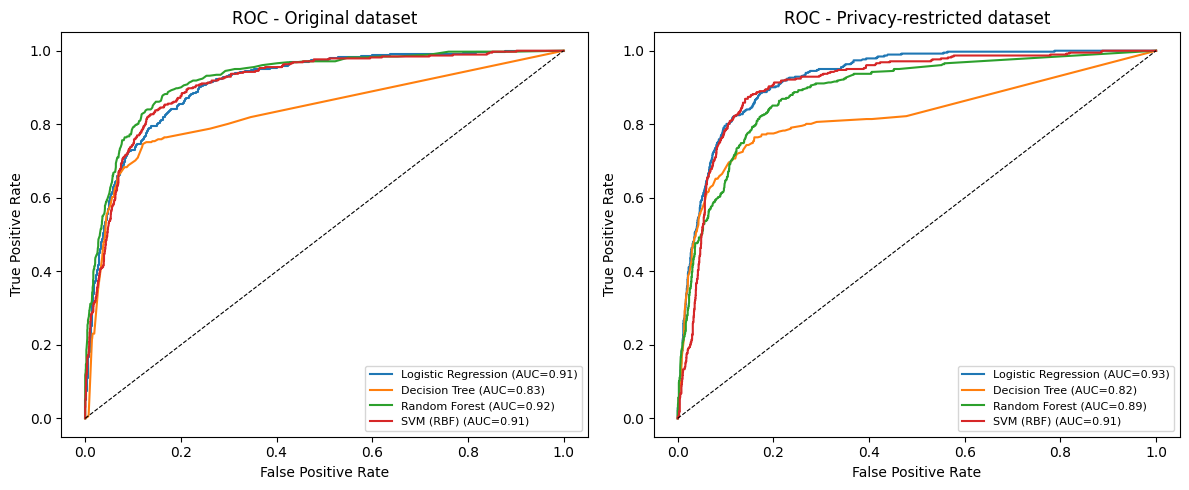

In [ ]:
# ROC curves: original vs privacy-restricted
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, (fpr, tpr, _) in roc_original.items():
    auc = results_original.loc[results_original.Model == name, 'AUC'].values[0]
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={auc:.2f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[0].set_title('ROC - Original dataset')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(fontsize=8)

for name, (fpr, tpr, _) in roc_restricted.items():
    auc = results_restricted.loc[results_restricted.Model == name, 'AUC'].values[0]
    axes[1].plot(fpr, tpr, label=f'{name} (AUC={auc:.2f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[1].set_title('ROC - Privacy-restricted dataset')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


##ADDITIONAL ANALYSIS

Confusion matrices for the 80:20 split, and a robustness check using repeated stratified 5-fold cross-validation (10 repeats) with Nadeau-Bengio corrected 95% confidence intervals. Results reproduce exactly with scikit-learn 1.6.1.

In [ ]:
# CONFUSION MATRICES AND PREDICTED-POSITIVE RATES ====
# Uses the same 80:20 stratified split (random_state=42) as run_experiment().
from sklearn.base import clone

conditions = {
    'Original': (X_original, numeric_cols_orig, categorical_cols_orig, None),
    'Privacy-restricted': (X_restricted, numeric_cols_restr, categorical_cols_restr, bin_cols_restr),
}

cm_rows = []
for label, (X, num, cat, binc) in conditions.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
    for name, clf in models.items():
        pipe = Pipeline([('prep', make_preprocessor(num, cat, binc)), ('clf', clone(clf))])
        pipe.fit(X_train, y_train)
        tn, fp, fn, tp = confusion_matrix(y_test, pipe.predict(X_test)).ravel()
        cm_rows.append({'Condition': label, 'Model': name, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                        'Predicted_positive_rate': round((tp + fp) / len(y_test), 4)})

cm_table = pd.DataFrame(cm_rows)
display(cm_table)


,Condition,Model,TN,FP,FN,TP,Predicted_positive_rate
0,Original,Logistic Regression,1761,298,78,304,0.2466
1,Original,Decision Tree,1796,263,95,287,0.2253
2,Original,Random Forest,1994,65,188,194,0.1061
3,Original,SVM (RBF),1827,232,88,294,0.2155
4,Privacy-restricted,Logistic Regression,1841,218,76,306,0.2147
5,Privacy-restricted,Decision Tree,1740,319,96,286,0.2478
6,Privacy-restricted,Random Forest,1917,142,164,218,0.1475
7,Privacy-restricted,SVM (RBF),1772,287,54,328,0.2519


In [ ]:
# ROBUSTNESS CHECK - REPEATED STRATIFIED 5-FOLD CV (10 REPEATS) ====
# The same folds are used for both conditions, so the differences are paired.
from sklearn.model_selection import RepeatedStratifiedKFold
from scipy import stats

N_SPLITS, N_REPEATS = 5, 10
METRICS = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)

cv_rows = []
for fold, (tr, te) in enumerate(rskf.split(X_original, y)):
    for label, (X, num, cat, binc) in conditions.items():
        for name, clf in models.items():
            pipe = Pipeline([('prep', make_preprocessor(num, cat, binc)), ('clf', clone(clf))])
            pipe.fit(X.iloc[tr], y.iloc[tr])
            y_pred = pipe.predict(X.iloc[te])
            y_proba = pipe.predict_proba(X.iloc[te])[:, 1]
            y_true = y.iloc[te]
            cv_rows.append({'Fold': fold, 'Condition': label, 'Model': name,
                            'Accuracy': accuracy_score(y_true, y_pred),
                            'Precision': precision_score(y_true, y_pred, zero_division=0),
                            'Recall': recall_score(y_true, y_pred),
                            'F1': f1_score(y_true, y_pred),
                            'AUC': roc_auc_score(y_true, y_proba)})
    print(f'fold {fold + 1}/{N_SPLITS * N_REPEATS} done')

cv_results = pd.DataFrame(cv_rows)

# Mean and standard deviation per model and condition
summary = cv_results.groupby(['Model', 'Condition'])[METRICS].agg(['mean', 'std']).round(4)
display(summary)


fold 1/50 done
fold 2/50 done
fold 3/50 done
fold 4/50 done
fold 5/50 done
fold 6/50 done
fold 7/50 done
fold 8/50 done
fold 9/50 done
fold 10/50 done
fold 11/50 done
fold 12/50 done
fold 13/50 done
fold 14/50 done
fold 15/50 done
fold 16/50 done
fold 17/50 done
fold 18/50 done
fold 19/50 done
fold 20/50 done
fold 21/50 done
fold 22/50 done
fold 23/50 done
fold 24/50 done
fold 25/50 done
fold 26/50 done
fold 27/50 done
fold 28/50 done
fold 29/50 done
fold 30/50 done
fold 31/50 done
fold 32/50 done
fold 33/50 done
fold 34/50 done
fold 35/50 done
fold 36/50 done
fold 37/50 done
fold 38/50 done
fold 39/50 done
fold 40/50 done
fold 41/50 done
fold 42/50 done
fold 43/50 done
fold 44/50 done
fold 45/50 done
fold 46/50 done
fold 47/50 done
fold 48/50 done
fold 49/50 done
fold 50/50 done


Accuracy         Precision          \
                                           mean     std      mean     std   
Model               Condition                                               
Decision Tree       Original             0.8467  0.0096    0.5070  0.0207   
                    Privacy-restricted   0.8434  0.0079    0.4998  0.0164   
Logistic Regression Original             0.8476  0.0081    0.5089  0.0176   
                    Privacy-restricted   0.8726  0.0054    0.5685  0.0145   
Random Forest       Original             0.8982  0.0050    0.7627  0.0231   
                    Privacy-restricted   0.8733  0.0057    0.5999  0.0209   
SVM (RBF)           Original             0.8680  0.0050    0.5569  0.0126   
                    Privacy-restricted   0.8564  0.0057    0.5255  0.0119   

                                        Recall              F1          \
                                          mean     std    mean     std   
Model               Condition                                            
Decision Tree       Original            0.7663  0.0253  0.6100  0.0187   
                    Privacy-restricted  0.7756  0.0242  0.6076  0.0149   
Logistic Regression Original            0.7589  0.0235  0.6091  0.0169   
                    Privacy-restricted  0.7727  0.0184  0.6548  0.0121   
Random Forest       Original            0.5068  0.0251  0.6087  0.0224   
                    Privacy-restricted  0.5705  0.0234  0.5845  0.0180   
SVM (RBF)           Original            0.7616  0.0211  0.6433  0.0131   
                    Privacy-restricted  0.8484  0.0196  0.6488  0.0101   

                                           AUC          
                                          mean     std  
Model               Condition                           
Decision Tree       Original            0.8544  0.0162  
                    Privacy-restricted  0.8554  0.0141  
Logistic Regression Original            0.9023  0.0061  
                    Privacy-restricted  0.9173  0.0055  
Random Forest       Original            0.9265  0.0061  
                    Privacy-restricted  0.8924  0.0067  
SVM (RBF)           Original            0.9058  0.0076  
                    Privacy-restricted  0.9093  0.0069

In [ ]:
#PAIRED DIFFERENCES WITH CORRECTED 95% CONFIDENCE INTERVALS ====
# Nadeau & Bengio (2003) corrected resampled t-test, in the repeated k-fold form
# given by Bouckaert & Frank (2004): variance is inflated by (1/(k*r) + n_test/n_train).
def corrected_ci(diffs, n_train, n_test):
    n = len(diffs)
    m, s2 = diffs.mean(), diffs.var(ddof=1)
    se = np.sqrt((1 / n + n_test / n_train) * s2)
    t_crit = stats.t.ppf(0.975, n - 1)
    p = 2 * stats.t.sf(abs(m / se), n - 1) if se > 0 else np.nan
    return m, m - t_crit * se, m + t_crit * se, p

n_test = len(y) / N_SPLITS
n_train = len(y) - n_test
diff_rows = []
for name in models:
    sub = cv_results[cv_results['Model'] == name]
    for metric in METRICS:
        w = sub.pivot(index='Fold', columns='Condition', values=metric)
        m, lo, hi, p = corrected_ci((w['Privacy-restricted'] - w['Original']).values, n_train, n_test)
        diff_rows.append({'Model': name, 'Metric': metric, 'Mean_difference': round(m, 4),
                          'CI_low': round(lo, 4), 'CI_high': round(hi, 4), 'p_value': round(p, 4)})

diff_table = pd.DataFrame(diff_rows)
display(diff_table)


,Model,Metric,Mean_difference,CI_low,CI_high,p_value
0,Logistic Regression,Accuracy,0.0250,0.0192,0.0308,0.0000
1,Logistic Regression,Precision,0.0595,0.0469,0.0721,0.0000
2,Logistic Regression,Recall,0.0138,-0.0033,0.0309,0.1117
3,Logistic Regression,F1,0.0458,0.0336,0.0579,0.0000
4,Logistic Regression,AUC,0.0150,0.0116,0.0185,0.0000
5,Decision Tree,Accuracy,-0.0033,-0.0148,0.0082,0.5654
6,Decision Tree,Precision,-0.0072,-0.0313,0.0170,0.5533
7,Decision Tree,Recall,0.0093,-0.0204,0.0390,0.5335
8,Decision Tree,F1,-0.0023,-0.0208,0.0162,0.8025
9,Decision Tree,AUC,0.0010,-0.0182,0.0202,0.9180


#SUMMARY OF FINDINGS

**Data.** The raw dataset had 12,330 sessions. After removing 125 exact duplicates, 12,205 sessions remained, of which 15.63% ended in a purchase. There were no missing values. PageValues was the feature most correlated with Revenue (r ≈ 0.49), and it is exactly zero in 77.6% of sessions, which is why the binning keeps zero as its own band.

**Conditions compared.**
- *Original:* 17 predictors.
- *Privacy-restricted:* 9 predictors.
  - Masking removed OperatingSystems, Browser, TrafficType and Region.
  - Minimisation removed the Administrative and Informational page counts and durations.
  - Aggregation grouped ProductRelated_Duration, BounceRates, ExitRates and PageValues into bands, with the bands learned from the training data only.

**Single 80:20 stratified split (ROC-AUC):**

| Model | Original | Restricted | Change |
|---|---|---|---|
| Logistic Regression | 0.9097 | 0.9258 | +0.0161 |
| Decision Tree | 0.8338 | 0.8235 | −0.0103 |
| Random Forest | 0.9239 | 0.8883 | −0.0356 |
| SVM (RBF) | 0.9095 | 0.9102 | +0.0007 |

- Logistic Regression improved on every metric. Precision rose from 0.505 to 0.584 and F1 from 0.618 to 0.676.
- Random Forest had the largest decline. Precision fell from 0.749 to 0.606 while recall rose from 0.508 to 0.571. The confusion matrices show it predicted a purchase for 14.7% of test sessions instead of 10.6%, and its false positives rose from 65 to 142.
- The SVM's AUC was unchanged, but it traded precision (0.559 → 0.533) for recall (0.770 → 0.859).

**Robustness check (repeated stratified 5-fold CV, 10 repeats, corrected 95% CIs):**
- *Confirmed:*
  - Logistic Regression improved (AUC +0.0150, F1 +0.0458).
  - Random Forest declined (AUC −0.0341, precision −0.1627, recall +0.0637).
  - The SVM shifted from precision (−0.0315) to recall (+0.0867).
- *Not confirmed:* the SVM's AUC change (+0.0035) and all of the Decision Tree's changes (AUC +0.0010).

**Conclusion.** The simulated restrictions did not reduce performance across the board. Their effect depended on the model:
- Logistic Regression clearly improved.
- Random Forest clearly declined.
- The SVM and the Decision Tree showed no detectable change in AUC.

**Caveats.**
- The study used one dataset, with all restrictions applied together as one condition.
- Hyperparameters were fixed rather than tuned.
- The reported values reproduce exactly only with scikit-learn 1.6.1.

## References

Full references are provided in the accompanying research report.

- Sakar, C. & Kastro, Y., 2018. Online Shoppers Purchasing Intention Dataset. UCI Machine Learning Repository. Licensed under CC BY 4.0. Available at: https://doi.org/10.24432/C5F88Q
- Sakar, C. O., Polat, S. O., Katircioglu, M. & Kastro, Y., 2019. Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks. Neural Computing and Applications, 31(10), pp. 6893-6908.
- Nadeau, C. & Bengio, Y., 2003. Inference for the generalization error. Machine Learning, 52, pp. 239-281.
- Bouckaert, R. R. & Frank, E., 2004. Evaluating the replicability of significance tests for comparing learning algorithms. In: Advances in Knowledge Discovery and Data Mining (PAKDD 2004). LNCS 3056. Berlin: Springer, pp. 3-12.
- Pedregosa, F. et al., 2011. Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, pp. 2825-2830.